# Practical 2: Factorial Calculation of N Numbers

### 1. Aim
To compute log-factorials across 3 independent tasks using Sequential execution, multiprocessing.Pool (3 workers), multiprocessing.Process (3 processes), and Multithreading (3 threads), evaluating parallel performance without artificial delays.

### 2. Algorithm / Explanation
1. Define 3 independent tasks calculating ln(100,000,000!) via chunked sum of logarithms in compiled C.<br>2. Sequential: calculate the 3 tasks sequentially.<br>3. Pool: distribute tasks to 3 worker processes via `pool.map()`.<br>4. Process: spawn 3 explicit `mp.Process` workers and collect results with `mp.Queue`.<br>5. Thread: execute 3 concurrent `threading.Thread` instances.<br>6. Verify numerical results and compare execution times.

### 3. Python Implementation


In [1]:
"""
Practical 2: Program to calculate factorial of N numbers
Pattern: Chunked calculation of ln(n!) for 3 independent tasks
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def factorial_task(n):
    total = 0.0
    chunk_size = 1_000_000
    for s in range(1, n + 1, chunk_size):
        e = min(s + chunk_size, n + 1)
        arr = np.arange(s, e, dtype=np.float64)
        total += float(np.sum(np.log(arr)))
    return total

def proc_worker(n, q):
    q.put(factorial_task(n))

def thread_worker(n, results, idx):
    results[idx] = factorial_task(n)

def main():
    print("=" * 60)
    print("Practical 2: Factorial of N Numbers")
    print("=" * 60)
    N = 100_000_000
    tasks = [N, N, N]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = factorial_task(tasks[0])
    r2 = factorial_task(tasks[1])
    r3 = factorial_task(tasks[2])
    t_seq = time.perf_counter() - t0
    seq_res = [r1, r2, r3]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(factorial_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    proc_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Calculated ln({N:,}!) across 3 independent tasks.")
    print(f"Sample ln(N!): {seq_res[0]:,.2f}")
    print(f"Results Match (Sequential == Thread): {seq_res[0] == thread_res[0]}")
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Practical 2: Factorial of N Numbers
Calculated ln(100,000,000!) across 3 independent tasks.
Sample ln(N!): 1,742,068,084.52
Results Match (Sequential == Thread): True
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   2.6881 seconds      1.00x
Pool         1.6986 seconds      1.58x
Process      1.8780 seconds      1.43x
Thread       1.0207 seconds      2.63x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process, and Thread with individual color bars.


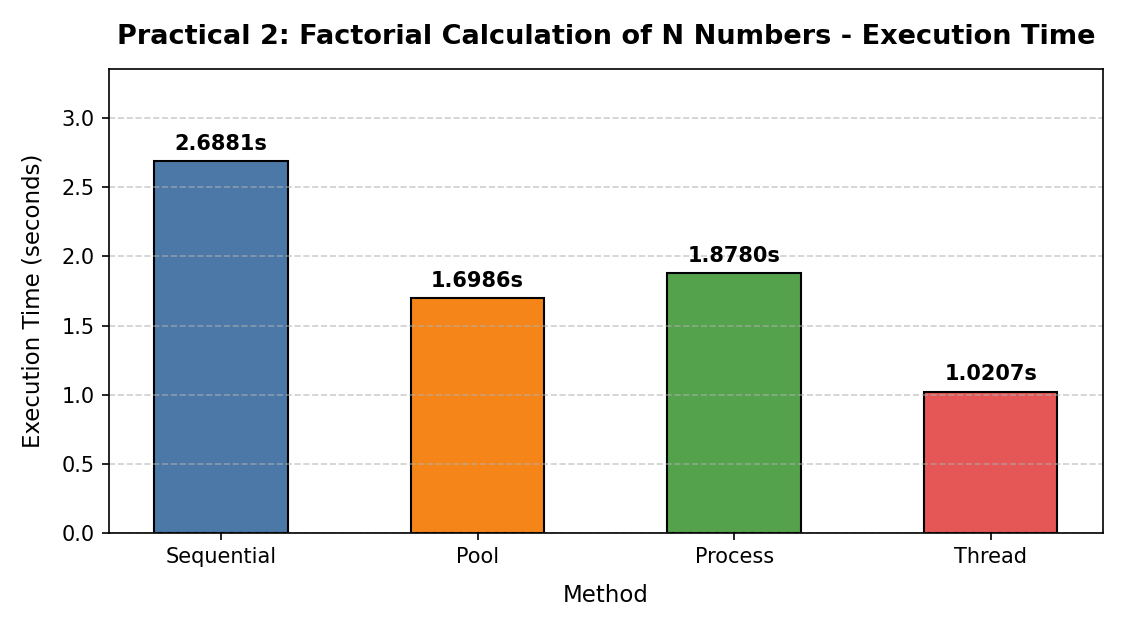

In [2]:
from IPython.display import Image, display
display(Image(filename='02_factorial_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


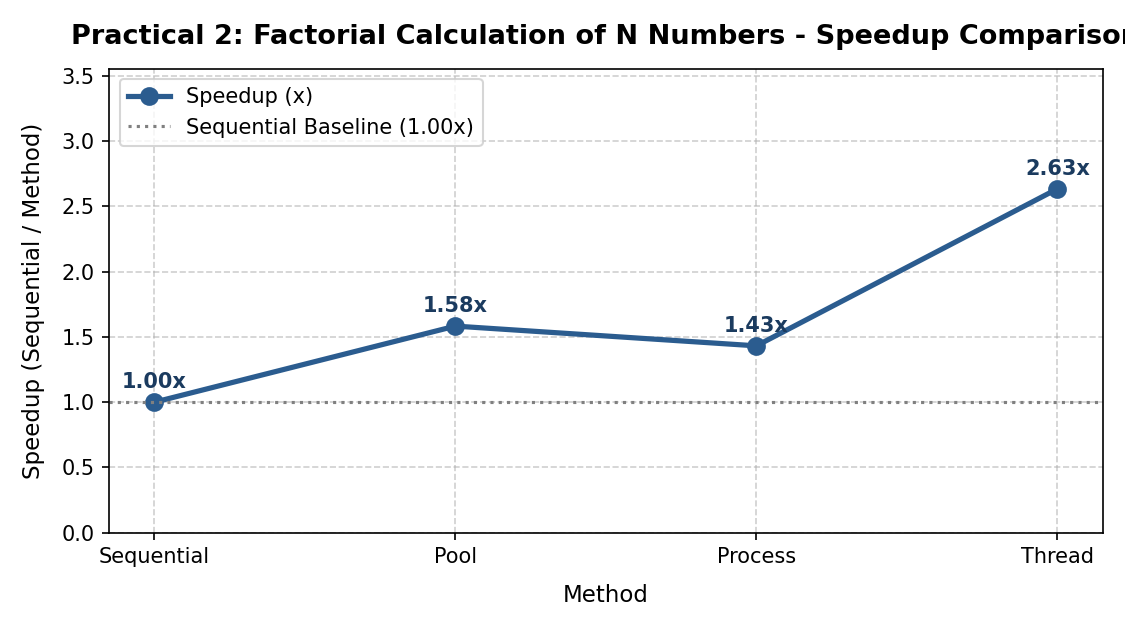

In [3]:
from IPython.display import Image, display
display(Image(filename='02_factorial_speedup.png'))
